# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Anjar Trianto
- NIM   : 241011400135
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [9]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 35   # isi dengan 2 digit terakhir NIM Anda

In [6]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    indices = np.arange(len(X))
    np.random.shuffle(indices)
    test_set_size = int(len(X) * test_size)
    test_indices = indices[:test_set_size]
    train_indices = indices[test_set_size:]

    if isinstance(X, (pd.DataFrame, pd.Series)):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]

    if isinstance(y, (pd.DataFrame, pd.Series)):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah total baris data: 40


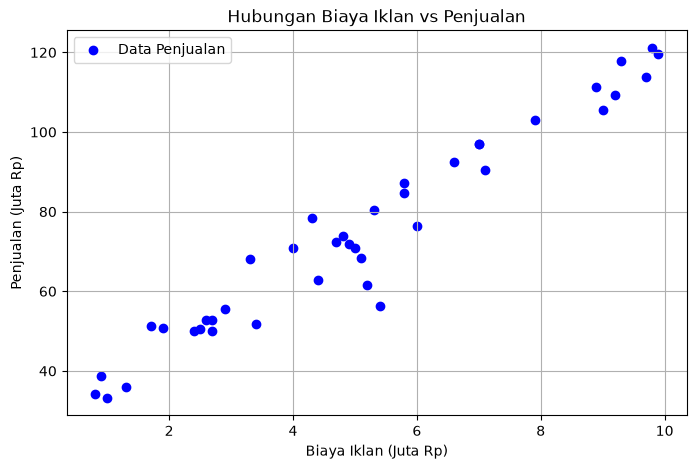

In [3]:
# Jawaban A1
# 1. Baca data & tampilkan
ads_df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
print(ads_df.head())
print(f"\nJumlah total baris data: {len(ads_df)}")

# 2. Pisahkan X (2D) dan y
X_ads = ads_df[['BiayaIklan']].values
y_ads = ads_df['Penjualan'].values

# 3. Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', label='Data Penjualan')
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [7]:
# Jawaban 
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_a.shape)
print("Shape X_test :", X_test_a.shape)
print("Shape y_train:", y_train_a.shape)
print("Shape y_test :", y_test_a.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [8]:
# Jawaban 
X_b_train_a = np.c_[np.ones((len(X_train_a), 1)), X_train_a]
theta_best = np.linalg.inv(X_b_train_a.T.dot(X_b_train_a)).dot(X_b_train_a.T.dot(y_train_a))

b = theta_best[0]
m = theta_best[1]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan Garis: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) : 28.0575
Koefisien (m) : 9.2366
Persamaan Garis: y_hat = 28.0575 + 9.2366 * X


**Jawaban A3 (interpretasi):**
Nilai koefisien $m \approx 9.24$ menunjukkan bahwa setiap kenaikan biaya iklan sebesar 1 juta Rp, perkiraan penjualan akan meningkat sebesar 9.24 juta Rp. Nilai intercept $b \approx 28.06$ berarti jika tidak ada biaya iklan ($X = 0$), basis penjualan awal adalah 28.06 juta Rp.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [10]:
# Jawaban 
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

y_train_pred_a = X_b_train_a.dot(theta_best)
X_b_test_a = np.c_[np.ones((len(X_test_a), 1)), X_test_a]
y_test_pred_a = X_b_test_a.dot(theta_best)

df_eval_a = pd.DataFrame({
    'Data': ['Training', 'Testing'],
    'MAE': [mae(y_train_a, y_train_pred_a), mae(y_test_a, y_test_pred_a)],
    'MSE': [mse(y_train_a, y_train_pred_a), mse(y_test_a, y_test_pred_a)],
    'RMSE': [rmse(y_train_a, y_train_pred_a), rmse(y_test_a, y_test_pred_a)],
    'R2': [r2_score(y_train_a, y_train_pred_a), r2_score(y_test_a, y_test_pred_a)]
})

print(df_eval_a)

       Data       MAE        MSE      RMSE        R2
0  Training  4.034892  33.015478  5.745910  0.951373
1   Testing  5.971847  49.756025  7.053795  0.866376


**Jawaban A4 (analisis):**
Nilai $R^2$ sebesar 0.866 pada data testing menunjukkan bahwa model mampu menjelaskan sekitar 86.6% variabilitas data penjualan dari variabel biaya iklan. Rata-rata error (RMSE) sekitar 7.05 juta Rp. Karena $R^2$ mendekati 1 dan eror relatif kecil, model regresi linear ini sudah tergolong baik.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR=0.001: Intercept=24.9394, Coef=9.7067
LR=0.02: Intercept=28.0575, Coef=9.2366
LR=0.1: Intercept=nan, Coef=nan


C:\Users\MyBook Hype\AppData\Local\Temp\ipykernel_14804\3125217755.py:18: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b.dot(self.theta))**2)
C:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\MyBook Hype\AppData\Local\Temp\ipykernel_14804\3125217755.py:16: RuntimeWarning: overflow encountered in dot
  gradients = (2/m_samples) * X_b.T.dot(X_b.dot(self.theta) - y)
C:\Users\MyBook Hype\AppData\Local\Temp\ipykernel_14804\3125217755.py:17: RuntimeWarning: invalid value encountered in subtract
  self.theta = self.theta - self.learning_rate * gradients
C:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


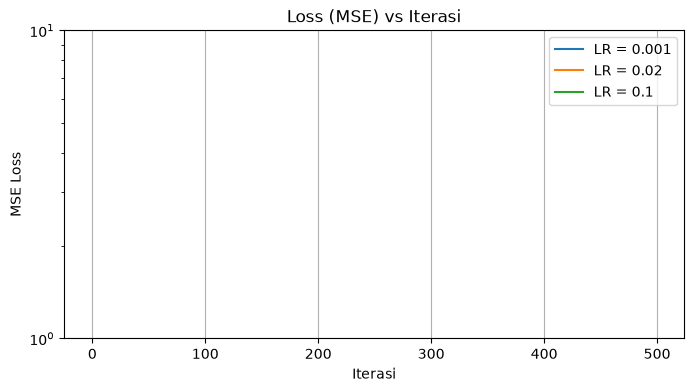

In [11]:
# Jawaban 
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.theta = None
        self.loss_history = []

    def fit(self, X, y):
        m_samples = len(y)
        X_b = np.c_[np.ones((m_samples, 1)), X]
        self.theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            gradients = (2/m_samples) * X_b.T.dot(X_b.dot(self.theta) - y)
            self.theta = self.theta - self.learning_rate * gradients
            loss = np.mean((y - X_b.dot(self.theta))**2)
            self.loss_history.append(loss)
        return self

lrs = [0.001, 0.02, 0.1]
plt.figure(figsize=(8, 4))

for lr in lrs:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train_a, y_train_a)
    print(f"LR={lr}: Intercept={model_gd.theta[0]:.4f}, Coef={model_gd.theta[1]:.4f}")
    plt.plot(model_gd.loss_history[:500], label=f'LR = {lr}')

plt.title('Loss (MSE) vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('MSE Loss')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**
Learning Rate 0.001: Terlalu lambat. Loss turun perlahan dan membutuhkan lebih banyak iterasi untuk mencapai titik optimal.

Learning Rate 0.02: Pas. Loss turun dengan stabil dan cepat mencapai nilai parameter yang sama persis dengan Normal Equation.

Learning Rate 0.1: Divergen (gagal konvergen). Karena nilainya terlalu besar, pencarian nilai minimum melompat terlalu jauh hingga terjadi pembebanan angka berlebih (overflow/NaN).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

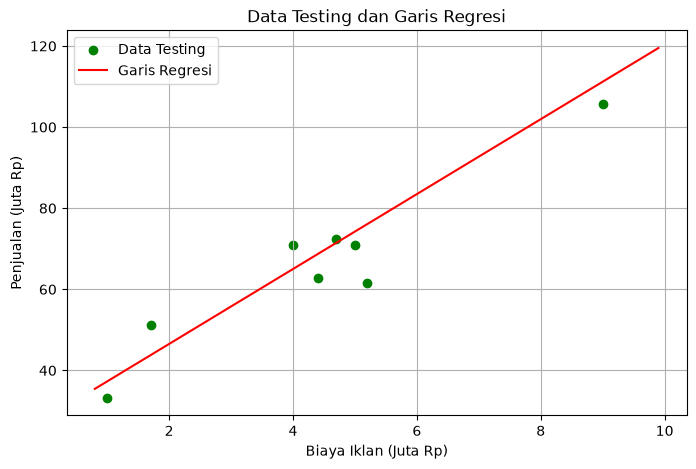

Prediksi biaya iklan 4.5 juta Rp -> Penjualan = 69.62 juta Rp
Prediksi biaya iklan 7.0 juta Rp -> Penjualan = 92.71 juta Rp
Prediksi biaya iklan 12.0 juta Rp -> Penjualan = 138.90 juta Rp


In [12]:
# Jawaban 
# 1. Plot data testing & garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='green', label='Data Testing')
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = theta_best[0] + theta_best[1] * x_line
plt.plot(x_line, y_line, color='red', label='Garis Regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi
for val in [4.5, 7.0, 12.0]:
    pred = theta_best[0] + theta_best[1] * val
    print(f"Prediksi biaya iklan {val} juta Rp -> Penjualan = {pred:.2f} juta Rp")

**Jawaban A6 (analisis):**
Prediksi untuk iklan 12 juta Rp kurang dapat dipercaya sepenuhnya karena nilai tersebut berada di luar jangkauan sampel data asli (ekstrapolasi). Pada kondisi riil, peningkatan biaya iklan tidak akan selalu mendatangkan kenaikan penjualan secara linear tanpa batas.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam & Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


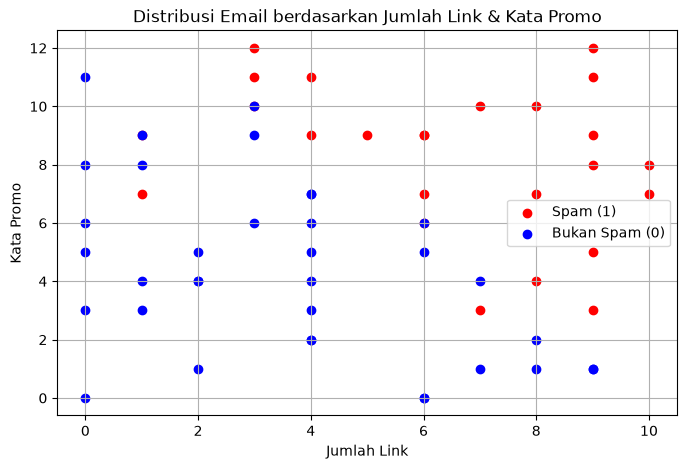

In [13]:
# Jawaban 
email_df = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email:")
print(email_df.head())
print("\nJumlah Email Spam & Bukan Spam:")
print(email_df['Spam'].value_counts())

X_email = email_df[['JumlahLink', 'KataPromo']].values
y_email = email_df['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 1][:, 0], X_email[y_email == 1][:, 1], color='red', label='Spam (1)')
plt.scatter(X_email[y_email == 0][:, 0], X_email[y_email == 0][:, 1], color='blue', label='Bukan Spam (0)')
plt.title('Distribusi Email berdasarkan Jumlah Link & Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Bias (b): -8.3149
Weights (m1, m2): 0.7693, 0.6854


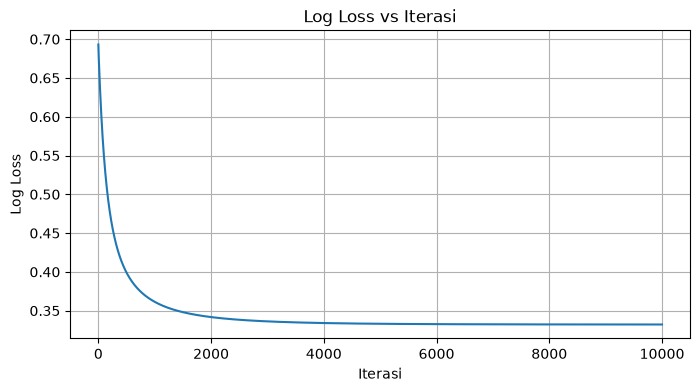

In [14]:
# Jawaban 
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []

        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            epsilon = 1e-15
            y_pred_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = - (1 / n_samples) * np.sum(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)

        return self

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_log = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_b, y_train_b)

print(f"Bias (b): {model_log.bias:.4f}")
print(f"Weights (m1, m2): {model_log.weights[0]:.4f}, {model_log.weights[1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(model_log.loss_history)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**
Nilai log loss menurun tajam pada iterasi awal dan mulai stabil sekitar iterasi ke-4000. Hal ini menandakan bahwa proses training berhasil konvergen dengan baik.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [15]:
# Jawaban 
def confusion_matrix_custom(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def accuracy_custom(y_true, y_pred):
    return np.mean(y_true == y_pred)

def precision_custom(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_custom(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_custom(y_true, y_pred):
    p = precision_custom(y_true, y_pred)
    r = recall_custom(y_true, y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

y_test_pred_b = model_log.predict(X_test_b, threshold=0.5)

print("Confusion Matrix:\n", confusion_matrix_custom(y_test_b, y_test_pred_b))
print(f"Accuracy : {accuracy_custom(y_test_b, y_test_pred_b):.4f}")
print(f"Precision: {precision_custom(y_test_b, y_test_pred_b):.4f}")
print(f"Recall   : {recall_custom(y_test_b, y_test_pred_b):.4f}")
print(f"F1-Score : {f1_custom(y_test_b, y_test_pred_b):.4f}")

Confusion Matrix:
 [[7 0]
 [0 8]]
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


**Jawaban B3 (analisis):**
alse Positive (FP): Email penting yang salah dikira spam lalu terbuang ke folder Spam.

False Negative (FN): Email spam yang terlepas dan masuk ke Inbox utama.
FP jauh lebih merugikan karena pengguna bisa kehilangan informasi penting (seperti surat resmi universitas atau pekerjaan) yang tidak sengaja terabaikan di folder spam.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

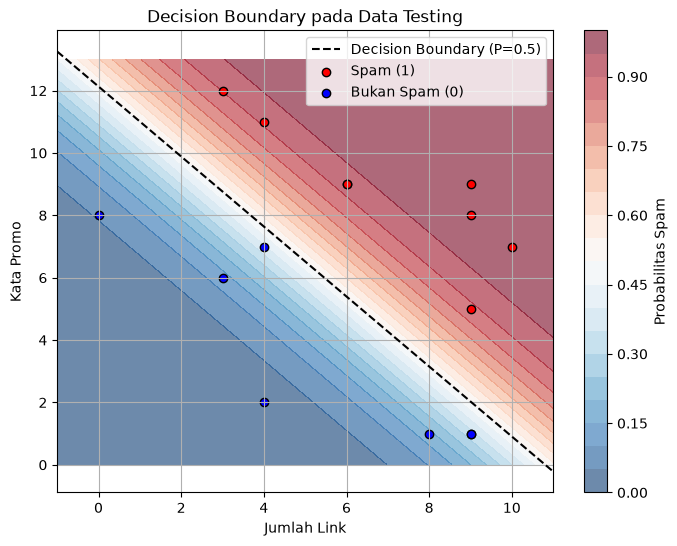

In [16]:
# Jawaban 
x1_min, x1_max = X_test_b[:, 0].min() - 1, X_test_b[:, 0].max() + 1
x2_min, x2_max = X_test_b[:, 1].min() - 1, X_test_b[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))

Z = model_log.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, Z, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(model_log.bias + model_log.weights[0] * x1_line) / model_log.weights[1]
plt.plot(x1_line, x2_line, 'k--', label='Decision Boundary (P=0.5)')

plt.scatter(X_test_b[y_test_b == 1][:, 0], X_test_b[y_test_b == 1][:, 1], color='red', edgecolors='k', label='Spam (1)')
plt.scatter(X_test_b[y_test_b == 0][:, 0], X_test_b[y_test_b == 0][:, 1], color='blue', edgecolors='k', label='Bukan Spam (0)')

plt.title('Decision Boundary pada Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban B4 (analisis):**
Berdasarkan garis pemisah (decision boundary), seluruh titik data testing dapat dipisahkan secara sempurna sesuai dengan kelasnya tanpa ada data yang salah diklasifikasikan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [17]:
# Jawaban 
results = []
for t in [0.3, 0.5, 0.7]:
    y_pred_t = model_log.predict(X_test_b, threshold=t)
    cm_t = confusion_matrix_custom(y_test_b, y_pred_t)
    results.append({
        'Threshold': t,
        'TN': cm_t[0, 0], 'FP': cm_t[0, 1],
        'FN': cm_t[1, 0], 'TP': cm_t[1, 1],
        'Accuracy': accuracy_custom(y_test_b, y_pred_t),
        'Precision': precision_custom(y_test_b, y_pred_t),
        'Recall': recall_custom(y_test_b, y_pred_t),
        'F1-Score': f1_custom(y_test_b, y_pred_t)
    })

print(pd.DataFrame(results))

   Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall  F1-Score
0        0.3   4   3   0   8       0.8   0.727273     1.0  0.842105
1        0.5   7   0   0   8       1.0   1.000000     1.0  1.000000
2        0.7   7   0   0   8       1.0   1.000000     1.0  1.000000


**Jawaban B5 (analisis):**
Menaikkan threshold akan memperketat kriteria klasifikasi spam sehingga meningkatkan nilai Precision (menekan angka False Positive). Threshold 0.5 atau 0.7 menjadi pilihan terbaik untuk filter spam guna menghindari salah deteksi pada email penting.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [18]:
# Jawaban 
new_emails = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

probas = model_log.predict_proba(new_emails)
preds = model_log.predict(new_emails, threshold=0.5)

for i, code in enumerate(['E1', 'E2', 'E3', 'E4']):
    label = "Spam (1)" if preds[i] == 1 else "Bukan Spam (0)"
    print(f"Email {code}: Probabilitas = {probas[i]:.4f} -> Prediksi = {label}")

Email E1: Probabilitas = 0.0021 -> Prediksi = Bukan Spam (0)
Email E2: Probabilitas = 0.4119 -> Prediksi = Bukan Spam (0)
Email E3: Probabilitas = 0.9958 -> Prediksi = Spam (1)
Email E4: Probabilitas = 0.6820 -> Prediksi = Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression dikategorikan sebagai algoritma klasifikasi karena output akhirnya berbentuk nilai kelas diskrit (0 atau 1). Kata "regression" tetap digunakan karena cara kerjanya secara internal menghitung kombinasi linear fitur seperti pada regresi. Fungsi sigmoid berperan memetakan hasil perhitungan linear tersebut menjadi probabilitas kontinu dengan rentang nilai antara 0 hingga 1.

**Jawaban C2:**
Normal equation menghitung parameter optimal secara matematis langsung lewat operasi invers matriks tanpa iterasi, sedangkan gradient descent mencari parameter optimal lewat pembaruan bertahap menggunakan turunan fungsi loss. Gradient descent lebih unggul dan disarankan jika dataset memiliki jumlah fitur dan sampel data yang sangat besar karena komputasi invers matriks menjadi sangat berat.

**Jawaban C3:**
Evaluasi pada data testing wajib dilakukan untuk menguji performa model terhadap data baru yang belum pernah dipelajari sebelumnya. Overfitting adalah kondisi di mana model menghafal data training secara berlebihan termasuk noise-nya, sehingga akurasinya sangat tinggi di data training namun jeblok saat diuji pada data testing.

**Jawaban C4:**
Linear Regression menggunakan Mean Squared Error (MSE) karena outputnya berupa nilai kontinu sehingga perhitungan kuadrat selisih angka riil sangat sesuai. Sementara Logistic Regression menghasilkan output probabilitas, sehingga memerlukan log loss yang memberikan hukuman (penalty) logaritmik yang besar jika model salah memprediksi kelas dengan tingkat kepercayaan tinggi.

**Jawaban C5:**
Perbedaan hasil kalkulasi antar mahasiswa terjadi karena penggunaan variabel `RANDOM_STATE` berbasis 2 digit terakhir NIM. Nilai acak ini memengaruhi urutan pengacakan (*shuffle*) saat pemisahan data training dan testing, sehingga tiap mahasiswa melatih modelnya pada kombinasi data sampel yang sedikit berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [19]:
# Jawaban 
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

sk_lin = SkLinearRegression()
sk_lin.fit(X_train_a, y_train_a)
print("=== Linear Regression ===")
print(f"Implementasi NumPy : Intercept = {b:.4f}, Coef = {m:.4f}")
print(f"Scikit-Learn       : Intercept = {sk_lin.intercept_:.4f}, Coef = {sk_lin.coef_[0]:.4f}")

sk_log = SkLogisticRegression(penalty=None)
sk_log.fit(X_train_b, y_train_b)
print("\n=== Logistic Regression (Penalty=None) ===")
print(f"Implementasi NumPy : Bias = {model_log.bias:.4f}, Weights = {model_log.weights[0]:.4f}, {model_log.weights[1]:.4f}")
print(f"Scikit-Learn       : Bias = {sk_log.intercept_[0]:.4f}, Weights = {sk_log.coef_[0][0]:.4f}, {sk_log.coef_[0][1]:.4f}")

=== Linear Regression ===
Implementasi NumPy : Intercept = 28.0575, Coef = 9.2366
Scikit-Learn       : Intercept = 28.0575, Coef = 9.2366

=== Logistic Regression (Penalty=None) ===
Implementasi NumPy : Bias = -8.3149, Weights = 0.7693, 0.6854
Scikit-Learn       : Bias = -8.4843, Weights = 0.7848, 0.6994


C:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**
Hasil model Linear Regression antara implementasi manual NumPy dan library scikit-learn bernilai persis sama. Pada Logistic Regression, saat parameter penalty=None dipasang di scikit-learn, hasil koefisien dan bias bernilai hampir identik dengan implementasi NumPy. Perbedaan minor dapat terjadi akibat perbedaan teknik optimasi (seperti algoritma L-BFGS pada scikit-learn).